# Знако-ранговая карта Шухарта (Shewhart Signed-Rank Chart)

**Непараметрическая контрольная карта для мониторинга медианы симметричного непрерывного распределения.**

Основано на главе 4 книги:

> Chakraborti, S. and Graham, M.A. (2019). *Nonparametric Statistical Process Control*, John Wiley & Sons Ltd.

---

## Содержание

1. [Импорты и настройка](#1-Импорты-и-настройка)
2. [Теория знако-ранговой карты](#2-Теория-знако-ранговой-карты-Шухарта)
    - 2.1. Постановка задачи
    - 2.2. Абсолютные отклонения и ранги
    - 2.3. Знако-ранговая статистика $SR_i$
    - 2.4. Связь со статистикой Уилкоксона $T_n^+$
    - 2.5. Распределение $SR_i$ в IC
    - 2.6. Моменты $T_n^+$ и $SR_i$
    - 2.7. Контрольные границы
    - 2.8. Distribution-free свойство
    - 2.9. Распределение длины серии
    - 2.10. Связь с классическим знаково-ранговым тестом
3. [Выбор целевого значения $\mu_0$](#3-Выбор-целевого-значения-μ0)
4. [Три подхода к расчёту константы $a$](#4-Три-подхода-к-расчёту-константы-a)
5. [Реализация функций](#5-Реализация-функций)
6. [Сравнение подходов](#6-Сравнение-подходов)
7. [Примеры 4.4–4.5 из книги](#7-Численные-примеры-из-книги)
8. [Сравнение со знаковой картой](#8-Сравнение-со-знаковой-картой)
9. [Моделирование длины серии](#9-Моделирование-длины-серии)
10. [Пользовательские данные data.csv](#10-Пользовательские-данные-datacsv)
11. [Итоги](#11-Итоги)

---

## 1. Импорты и настройка

In [1]:
import sys
import os
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import binom, geom, probplot
from scipy.special import comb

warnings.filterwarnings('ignore')
np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['lines.linewidth'] = 1.5
pd.set_option('display.max_columns', 50)
pd.set_option('display.precision', 6)

# Корень проекта
PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = Path(os.getcwd()).resolve()
sys.path.insert(0, str(PROJECT_ROOT))
print(f'PROJECT_ROOT = {PROJECT_ROOT}')

DATA_PATH = PROJECT_ROOT / 'data' / 'data.csv'
print(f'DATA_PATH = {DATA_PATH}, существует: {DATA_PATH.exists()}')

PROJECT_ROOT = /home/nebolsinvasili/Projects/nparametric-charts
DATA_PATH = /home/nebolsinvasili/Projects/nparametric-charts/data/data.csv, существует: True


In [2]:
# Принудительная перезагрузка модуля
import importlib
try:
    import src.charts.signed_rank_chart
    importlib.reload(src.charts.signed_rank_chart)
    from src.charts.signed_rank_chart import SignedRankChart
    print('SignedRankChart успешно импортирован (с reload)')
except Exception as e:
    print(f'Ошибка импорта: {e}')
    print('Будем использовать локальные функции из этого ноутбука.')

SignedRankChart успешно импортирован (с reload)


---

## 2. Теория знако-ранговой карты Шухарта

**Источник:** Section 4.2.1.2 «Shewhart Control Charts Based on Signed-ranks», стр. 196–202.

### 2.1. Постановка задачи *(стр. 197)*

Рассматривается процесс, из которого через равные промежутки времени берутся независимые подгруппы размера $n > 1$:

$$X_{i1}, X_{i2}, \ldots, X_{in}, \quad i = 1, 2, 3, \ldots$$

**Предположения:**

1. Наблюдения **независимы** внутри подгруппы и между подгруппами.
2. Распределение $F$ **непрерывно и симметрично** относительно неизвестного центра $\mu$.
3. Целевое значение $\mu_0$ (IC-медиана) **известно** — это Case K.

Так как распределение симметрично, среднее и медиана совпадают. Это делает знако-ранговую карту **прямым аналогом** параметрической карты $\bar{X}$ (для нормального распределения), но без требования нормальности.

### 2.2. Абсолютные отклонения и ранги *(стр. 197)*

Для каждого наблюдения вычисляется **абсолютное отклонение** от $\mu_0$:

$$D_{ij} = |X_{ij} - \mu_0|$$

Затем внутри $i$-й подгруппы эти отклонения **ранжируются** от 1 до $n$. Обозначим ранг как $R_{ij}$.

**Важно:** ранжирование происходит **внутри каждой подгруппы отдельно**, а не по всем данным сразу. Это ключевое отличие от подхода Phase I (mean-rank chart).

**При наличии совпадений** используется средний ранг: если $k$ наблюдений имеют одинаковое $D$, каждому присваивается средний из $k$ последовательных рангов.

### 2.3. Знако-ранговая статистика *(стр. 197, ур. 4.5)*

**Статистика $SR_i$:**

$$\boxed{SR_i = \sum_{j=1}^{n} \phi(X_{ij} - \mu_0) \cdot R_{ij}}$$

где $\phi(t) = +1$ при $t > 0$, $-1$ при $t < 0$, $0$ при $t = 0$.

**Словесно:** $SR_i$ — это **разность между суммой рангов положительных отклонений и суммой рангов отрицательных отклонений**.

**Обозначения:**
- $S_i^+ = \sum_{j: X_{ij} > \mu_0} R_{ij}$ — сумма рангов «+»
- $S_i^- = \sum_{j: X_{ij} < \mu_0} R_{ij}$ — сумма рангов «−»
- $SR_i = S_i^+ - S_i^-$

Так как $S_i^+ + S_i^- = \frac{n(n+1)}{2} = S$:

$$\boxed{SR_i = 2 S_i^+ - S = 2 S_i^+ - \frac{n(n+1)}{2}}$$

### 2.4. Связь со статистикой Уилкоксона $T_n^+$ *(стр. 197)*

**Классическая статистика знаковых рангов Уилкоксона:**

$$T_n^+ = \sum_{j=1}^{n} \Psi(X_{ij} - \mu_0) \cdot R_{ij}$$

где $\Psi(t) = 1$ при $t > 0$ и $0$ иначе. То есть $T_n^+ = S_i^+$.

**Связь:**

$$\boxed{SR_i = 2 T_n^+ - \frac{n(n+1)}{2}}$$

Это **линейное преобразование** — знание распределения $T_n^+$ автоматически даёт распределение $SR_i$.

### 2.5. Распределение $SR_i$ в IC-состоянии *(стр. 199–200)*

В отличие от $SN_i$ (биномиальное), распределение $SR_i$ **не имеет замкнутой формы**. Оно получается **точным перебором** всех $2^n$ знаковых комбинаций рангов $1, \ldots, n$:

$$SR_i = \sum_{j=1}^{n} s_j \cdot j, \quad s_j \in \{-1, +1\}$$

Каждая из $2^n$ комбинаций $(s_1, \ldots, s_n)$ равновероятна (вероятность $2^{-n}$) в IC-состоянии, поскольку $P(X_{ij} > \mu_0) = 0.5$.

**Диапазон значений:** $SR_i \in \{-S, -S+2, \ldots, S-2, S\}$, где $S = \frac{n(n+1)}{2}$. Шаг равен 2.

**Симметрия:**

$$P(SR_i = k) = P(SR_i = -k), \quad \forall k$$

Это следствие симметрии распределения $X$ относительно $\mu_0$.

**Точное вычисление вероятностей** (для небольших $n$):

```python
from itertools import product
S = n * (n + 1) // 2
dist = {}
for signs in product([-1, 1], repeat=n):
    sr = sum(s * j for j, s in enumerate(signs, start=1))
    dist[sr] = dist.get(sr, 0) + 1
for k in dist:
    dist[k] /= 2 ** n
```

### 2.6. Моменты $T_n^+$ и $SR_i$ *(стр. 200)*

| Величина | $T_n^+$ | $SR_i$ |
|---|---|---|
| **Математическое ожидание** | $E(T_n^+) = \dfrac{n(n+1)}{4}$ | $E(SR_i) = 0$ |
| **Стандартное отклонение** | $\sqrt{\dfrac{n(n+1)(2n+1)}{24}}$ | $\sqrt{\dfrac{n(n+1)(2n+1)}{6}}$ |

**Проверка через связь $SR_i = 2T_n^+ - S$:**

$$E(SR_i) = 2 \cdot \frac{n(n+1)}{4} - \frac{n(n+1)}{2} = 0 \; \checkmark$$

$$\text{Var}(SR_i) = 4 \cdot \frac{n(n+1)(2n+1)}{24} = \frac{n(n+1)(2n+1)}{6} \; \checkmark$$

### 2.7. Контрольные границы *(стр. 198, ур. 4.6)*

$$\boxed{UCL = +a, \quad CL = 0, \quad LCL = -a}$$

где $a$ — положительное целое, $0 < a \le \frac{n(n+1)}{2} = S$.

**Правило сигнала:**

$$\text{Процесс OOC} \;\Longleftrightarrow\; |SR_i| \ge a \;\Longleftrightarrow\; SR_i \ge a \text{ или } SR_i \le -a$$

**Односторонние версии:**
- Верхняя: сигнал при $SR_i \ge a$
- Нижняя: сигнал при $SR_i \le -a$

### 2.8. Distribution-free свойство

**Теорема.** Знако-ранговая карта Шухарта является distribution-free **для класса непрерывных симметричных распределений**.

**Доказательство.**
1. $SR_i$ зависит только от знаков и рангов $|X_{ij} - \mu_0|$.
2. При симметричном $F$ и $\mu_0$ = центр симметрии: $P(X_{ij} > \mu_0) = P(X_{ij} < \mu_0) = 0.5$.
3. Ранги абсолютных отклонений **не зависят** от конкретного вида $F$ (при непрерывности).
4. Следовательно, распределение $SR_i$ **одинаково** для всех непрерывных симметричных $F$. $\blacksquare$

**Важно:** симметрия — **обязательное** условие. Для асимметричных распределений (экспоненциальное, гамма с $\alpha \ne 1$, логнормальное) знако-ранговая карта **не является** distribution-free, и её IC-свойства зависят от $F$. В таких случаях используйте **знаковую карту** (она distribution-free для всех непрерывных $F$).

**Компромисс:**
- Знаковая карта: только непрерывность, но ниже мощность.
- Знако-ранговая карта: выше мощность, но требует симметрии.

### 2.9. Распределение длины серии *(стр. 199)*

**В Case K** длина серии $N$ имеет **геометрическое распределение**:

$$\boxed{N \sim \text{GEO}(\theta)}, \quad \theta = FAR = P(|SR_i| \ge a)$$

Все характеристики — те же, что у знаковой карты:

| Величина | Формула |
|----------|---------|
| $ARL$ | $1/\theta$ |
| $SDRL$ | $\sqrt{1-\theta}/\theta$ |
| $MRL$ | $\lceil \ln 0.5 / \ln(1-\theta) \rceil$ |
| $p$-й процентиль | $\lceil \ln(1-p) / \ln(1-\theta) \rceil$ |

**Отличие от знаковой карты:** здесь $\theta = 2 \cdot P(SR_i \ge a)$ вычисляется через **точное распределение** $SR_i$ (перебор), а не через биномиальное.

### 2.10. Связь с классическим знаково-ранговым тестом *(стр. 197)*

Статистика $T_n^+$ — основа **одновыборочного знаково-рангового теста Уилкоксона** для проверки:

$$H_0: \text{медиана} = \mu_0 \quad \text{против} \quad H_1: \text{медиана} \neq \mu_0$$

при условии симметрии распределения.

Асимптотически (при $n \to \infty$):

$$Z = \frac{T_n^+ - n(n+1)/4}{\sqrt{n(n+1)(2n+1)/24}} \xrightarrow{d} N(0,1)$$

Знако-ранговая карта — это **последовательное применение** этого теста к каждой подгруппе.

---

## 3. Выбор целевого значения $\mu_0$

### 3.1. Проблема

Контрольные границы знако-ранговой карты строятся относительно $\mu_0$ — целевого значения (IC-медианы). Возможны три ситуации:

1. **$\mu_0$ известно из инженерных соображений** — используем напрямую (Case K).
2. **$\mu_0$ неизвестно, но есть Phase I** — оцениваем как **медиану Phase I** данных (Case U).
3. **$\mu_0$ неизвестно, Phase I нет** — используем медиану **всех данных**.

### 3.2. Почему медиана и почему симметрия?

1. **Согласованность:** знако-ранговая статистика измеряет отклонение от $\mu_0$. При симметричном $F$ и $\mu_0$ = центр симметрии: $P(X_{ij} > \mu_0) = P(X_{ij} < \mu_0) = 0.5$, что даёт корректную нулевую гипотезу.

2. **Проверка симметрии:** перед применением карты **настоятельно рекомендуется** проверить симметрию данных (гистограмма, QQ-plot, тест Ходжеса-Лемана). Если симметрия нарушена — используйте **знаковую карту**.

3. **Робастность:** медиана устойчива к выбросам.

### 3.3. Реализация в классе `SignedRankChart`

```python
if target_value is None:
    self.target_value = self._calculate_median()
else:
    self.target_value = float(target_value)
```

### 3.4. Практическая рекомендация

- **По умолчанию** — медиана всех данных.
- **Если есть спецификация** — задавайте $\mu_0$ явно.
- **Если есть Phase I** — медиана **по Phase I**.
- **Обязательно** проверяйте симметрию: `scipy.stats.skew`, `probplot`, тест Ходжеса-Лемана.

---

## 4. Три подхода к расчёту константы $a$

### 4.1. Постановка задачи

Константа $a$ определяет ширину контрольных границ $\pm a$. Она выбирается так, чтобы обеспечить желаемое значение $FAR$ (или $\alpha$).

**Ключевая формула для двусторонней карты:**

$$FAR = P(|SR_i| \ge a) = 2 \cdot P(SR_i \ge a)$$

где $P(SR_i \ge a)$ вычисляется через **точное распределение** $SR_i$ (перебор $2^n$ комбинаций).

### 4.2. Консервативный подход (по книге, стр. 198)

**Определение:**

$$\boxed{a = \text{наименьшее целое}: \; P(SR \ge a) \le \frac{FAR_0}{2}}$$

**Алгоритм:**
1. Для $a = 1, 2, \ldots, S$ (где $S = n(n+1)/2$) вычислить $P(SR \ge a)$.
2. Найти **наименьшее** $a$, для которого $P(SR \ge a) \le FAR_0/2$.

**Свойство:** гарантирует $FAR \le FAR_0$.

**Промышленный стандарт:** $FAR_0 = 0.0027$.

**Пример из книги (стр. 198–199):**

- $n = 4$: $S = 10$. $P(T_4^+ = 10) = 1/16 = 0.0625$. Наименьшее $a$ с $P(SR \ge a) \le 0.00135$ — это $a = 10$ (максимум). Достигнутый $FAR = 0.125$, $ARL_{IC} = 8$.
- $n = 13$: $S = 91$. Из таблицы B: $P(T_{13}^+ \ge 86) = 0.001$. Тогда $a = 2 \cdot 86 - 91 = 81$. Достигнутый $FAR = 0.002$, $ARL_{IC} = 500$.

### 4.3. Ближайший к $\alpha$

**Определение:**

$$\boxed{a = \arg\min_{a \in \{1, \ldots, S\}} |P(|SR| \ge a) - \alpha|}$$

**Свойство:** достигнутый $FAR$ может **превышать** $\alpha$.

**Применение:** обучение, сравнение с классическим тестом.

### 4.4. Симметричный квантильный

**Определение:** $a$ той же чётности, что и $S = n(n+1)/2$.

**Обоснование:** возможные значения $SR_i$ имеют шаг 2 и ту же чётность, что и $S$. Если $a$ имеет другую чётность, контрольные границы «не попадают» на возможные значения $SR_i$, что нарушает симметрию правила сигнала.

**Алгоритм:**
1. Вычислить $S = n(n+1)/2$.
2. Начать с $a_0 = S$, если $S$ чётное, или $a_0 = S - 1$ в противном случае (чтобы совпасть по чётности).
3. Идти вниз с шагом 2 до первого $a$, где $P(SR \ge a) \le FAR_0/2$.

**Пример:** $n = 5$, $S = 15$ (нечётное). Возможные значения $SR$: $-15, -13, \ldots, 13, 15$. Симметричный подход даст нечётное $a$.

### 4.5. Сравнение подходов

| Подход | Формула | Гарантия $FAR \le FAR_0$ | Применение |
|--------|---------|--------------------------|------------|
| Консервативный | $P(SR \ge a) \le FAR_0/2$ | Да | Стандарт SPC (книга) |
| Ближайший | $|P(|SR| \ge a) - \alpha| \to \min$ | Нет | Обучение, сравнение |
| Симметричный | Наименьшее с чётностью $S$ и $P(SR \ge a) \le FAR_0/2$ | Да | Симметрия границ |

---

## 5. Реализация функций

In [3]:
from itertools import product as iproduct
from functools import lru_cache


@lru_cache(maxsize=None)
def sr_distribution(n):
    """
    Точное распределение SR в IC для подгруппы размера n.
    Возвращает словарь {значение_SR: вероятность}.
    """
    S = n * (n + 1) // 2
    counts = {}
    for signs in iproduct([-1, 1], repeat=n):
        sr = sum(s * j for j, s in enumerate(signs, start=1))
        counts[sr] = counts.get(sr, 0) + 1
    total = 2 ** n
    return {k: v / total for k, v in counts.items()}


def p_sr_ge_a(n, a):
    """P(SR ≥ a) в IC."""
    dist = sr_distribution(n)
    return float(sum(p for v, p in dist.items() if v >= a))


def p_abs_sr_ge_a(n, a):
    """P(|SR| ≥ a) = 2·P(SR ≥ a) по симметрии."""
    if a <= 0:
        return 1.0
    return min(2.0 * p_sr_ge_a(n, a), 1.0)


def calc_a_conservative(n, far0=0.0027):
    """Консервативный подход: наименьшее a с P(SR ≥ a) ≤ FAR₀/2."""
    S = n * (n + 1) // 2
    target = far0 / 2
    for a in range(1, S + 1):
        if p_sr_ge_a(n, a) <= target:
            return a, 2.0 * p_sr_ge_a(n, a)
    return S, 2.0 * p_sr_ge_a(n, S)


def calc_a_nearest(n, alpha=0.05):
    """Ближайший к α."""
    S = n * (n + 1) // 2
    best = (1, 1.0, float('inf'))
    for a in range(1, S + 1):
        p = p_abs_sr_ge_a(n, a)
        d = abs(p - alpha)
        if d < best[2]:
            best = (a, p, d)
    return best[0], best[1]


def calc_a_symmetric(n, far0=0.0027):
    """Симметричный квантильный: a той же чётности, что и S."""
    S = n * (n + 1) // 2
    target = far0 / 2
    start = S if (S % 2 == 0) else S - 1
    for a in range(start, 0, -2):
        if p_sr_ge_a(n, a) <= target:
            return a, 2.0 * p_sr_ge_a(n, a)
    return 1, 2.0 * p_sr_ge_a(n, 1)


def sr_statistic(sample, mu0):
    """SR_i = Σ sign(X−μ₀)·rank(|X−μ₀|)."""
    sample = np.asarray(sample, dtype=float)
    dev = sample - mu0
    mask = dev != 0
    dev_nz = dev[mask]
    if len(dev_nz) == 0:
        return 0.0, 0.0
    ranks = stats.rankdata(np.abs(dev_nz), method='average')
    signs = np.sign(dev_nz)
    sr = float(np.sum(signs * ranks))
    T_plus = float(np.sum(ranks[signs > 0]))
    return sr, T_plus


def default_target_value(data, sample_size):
    """Медиана всех данных."""
    values = data.iloc[:, :sample_size].values.flatten()
    values = values[~np.isnan(values)]
    return float(np.median(values)) if len(values) > 0 else 0.0


def hodges_lehmann_symmetric_test(x):
    """
    Простой тест симметрии Ходжеса-Лемана.
    Возвращает статистику и p-value (асимптотически).
    """
    x = np.asarray(x)
    x = x[~np.isnan(x)]
    med = np.median(x)
    dev = x - med
    # Разбиваем на пары с противоположными знаками
    pos = dev[dev > 0]
    neg = -dev[dev < 0]
    if len(pos) == 0 or len(neg) == 0:
        return 0.0, 1.0
    # Статистика: разность медиан положительных и отрицательных отклонений
    stat = np.median(pos) - np.median(neg)
    # Простая нормальная аппроксимация (для демонстрации)
    n = len(x)
    se = np.sqrt(np.var(pos) / len(pos) + np.var(neg) / len(neg)) if len(pos) > 0 and len(neg) > 0 else 0
    z = stat / se if se > 0 else 0
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    return float(stat), float(p_value)

In [4]:
# Демонстрация: распределение SR для n = 4 и n = 5
for n_demo in [4, 5]:
    dist = sr_distribution(n_demo)
    S = n_demo * (n_demo + 1) // 2
    print(f'\nn = {n_demo}, S = {S}, диапазон SR = [{-S}, {S}], шаг 2')
    print(f'E(SR) = {sum(k*p for k,p in dist.items()):.6f}')
    print(f'Var(SR) = {sum(k**2*p for k,p in dist.items()):.6f}')
    print(f'Теория: E=0, Var={n_demo*(n_demo+1)*(2*n_demo+1)/6:.6f}')
    print(f'P(SR = S) = {dist[S]:.6f}, P(SR = -S) = {dist[-S]:.6f}')


n = 4, S = 10, диапазон SR = [-10, 10], шаг 2
E(SR) = 0.000000
Var(SR) = 30.000000
Теория: E=0, Var=30.000000
P(SR = S) = 0.062500, P(SR = -S) = 0.062500

n = 5, S = 15, диапазон SR = [-15, 15], шаг 2
E(SR) = 0.000000
Var(SR) = 55.000000
Теория: E=0, Var=55.000000
P(SR = S) = 0.031250, P(SR = -S) = 0.031250


---

## 6. Сравнение подходов

In [5]:
def compare_all(n, far0=0.0027, alpha=0.05):
    a_c, far_c = calc_a_conservative(n, far0)
    a_n, far_n = calc_a_nearest(n, alpha)
    a_s, far_s = calc_a_symmetric(n, far0)
    return [
        {'approach': 'conservative', 'a': a_c, 'FAR': far_c,
         'ARL_IC': 1/far_c if far_c > 0 else np.inf},
        {'approach': 'nearest', 'a': a_n, 'FAR': far_n,
         'ARL_IC': 1/far_n if far_n > 0 else np.inf},
        {'approach': 'symmetric', 'a': a_s, 'FAR': far_s,
         'ARL_IC': 1/far_s if far_s > 0 else np.inf},
    ]

rows = []
for n in [3, 4, 5, 6, 7, 8, 10, 13, 15, 20]:
    for r in compare_all(n):
        rows.append({'n': n, **r})
df_cmp = pd.DataFrame(rows)
df_cmp.pivot(index='n', columns='approach', values=['a', 'FAR', 'ARL_IC']).round(4)

a                            FAR                    \
approach conservative nearest symmetric conservative nearest symmetric   
n                                                                        
3                 6.0     5.0       1.0       0.2500  0.2500    0.7500   
4                10.0     9.0       1.0       0.1250  0.1250    0.8750   
5                15.0    14.0       1.0       0.0625  0.0625    1.0000   
6                21.0    18.0       1.0       0.0312  0.0625    1.0000   
7                28.0    23.0       1.0       0.0156  0.0469    0.9375   
8                36.0    27.0       1.0       0.0078  0.0547    0.9453   
10               54.0    38.0      54.0       0.0020  0.0488    0.0020   
13               80.0    56.0      90.0       0.0024  0.0479    0.0002   
15               99.0    69.0     120.0       0.0026  0.0479    0.0001   
20              155.0   105.0     210.0       0.0023  0.0484    0.0000   

               ARL_IC                        
approach conservative  nearest    symmetric  
n                                            
3              4.0000   4.0000       1.3333  
4              8.0000   8.0000       1.1429  
5             16.0000  16.0000       1.0000  
6             32.0000  16.0000       1.0000  
7             64.0000  21.3333       1.0667  
8            128.0000  18.2857       1.0579  
10           512.0000  20.4800     512.0000  
13           409.6000  20.8980    4096.0000  
15           381.0233  20.8713   16384.0000  
20           430.0968  20.6437  524288.0000

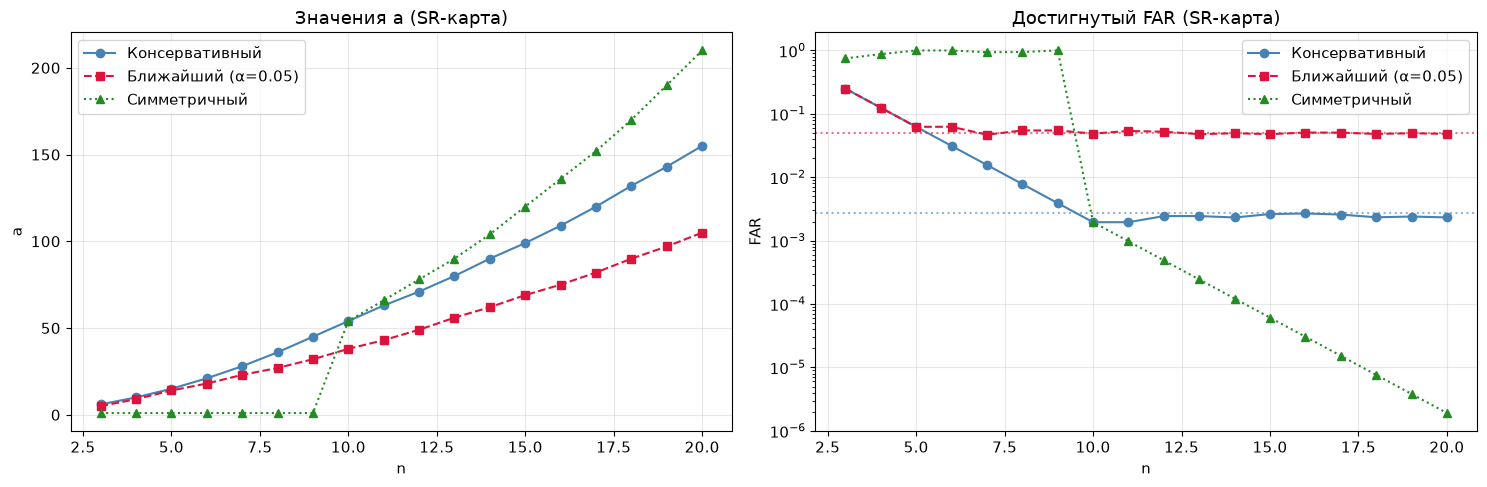

In [6]:
n_range = np.arange(3, 21)
data_plot = {'conservative': ([], []), 'nearest': ([], []), 'symmetric': ([], [])}
for n in n_range:
    a_c, f_c = calc_a_conservative(n)
    a_n, f_n = calc_a_nearest(n, 0.05)
    a_s, f_s = calc_a_symmetric(n)
    data_plot['conservative'][0].append(a_c); data_plot['conservative'][1].append(f_c)
    data_plot['nearest'][0].append(a_n); data_plot['nearest'][1].append(f_n)
    data_plot['symmetric'][0].append(a_s); data_plot['symmetric'][1].append(f_s)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {'conservative': 'steelblue', 'nearest': 'crimson', 'symmetric': 'forestgreen'}
styles = {'conservative': 'o-', 'nearest': 's--', 'symmetric': '^:'}

for key, label in [('conservative', 'Консервативный'),
                    ('nearest', 'Ближайший (α=0.05)'),
                    ('symmetric', 'Симметричный')]:
    axes[0].plot(n_range, data_plot[key][0], styles[key], color=colors[key], label=label)
    axes[1].plot(n_range, data_plot[key][1], styles[key], color=colors[key], label=label)

axes[0].set_xlabel('n'); axes[0].set_ylabel('a')
axes[0].set_title('Значения a (SR-карта)'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].axhline(0.0027, color='steelblue', linestyle=':', alpha=0.6)
axes[1].axhline(0.05, color='crimson', linestyle=':', alpha=0.6)
axes[1].set_xlabel('n'); axes[1].set_ylabel('FAR')
axes[1].set_title('Достигнутый FAR (SR-карта)'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_yscale('log')
plt.tight_layout(); plt.show()

---

## 7. Численные примеры из книги

### 7.1. Пример 4.4 — стр. 225–228 (Shewhart-SR chart)

20 подгрупп по $n = 4$. $\mu_0 = 0$. Симметричное распределение.

In [7]:
data_4_7a = np.array([
    [-0.39, 0.03, 0.25, 0.30],
    [-0.61, -1.32, -2.84, -0.07],
    [2.04, 0.40, 0.54, 1.12],
    [-0.51, -1.63, 0.28, -0.96],
    [-0.20, -0.01, -0.21, 0.82],
    [2.03, 0.70, -1.21, -0.26],
    [0.64, 1.48, 0.91, 1.23],
    [0.19, -2.74, -0.85, 1.25],
    [-0.51, -1.77, -1.69, 0.24],
    [-0.84, -0.71, -0.82, 0.19],
    [0.29, 0.47, 0.04, 0.39],
    [0.38, 2.18, 1.24, -0.80],
    [-0.86, 0.61, -0.70, -1.13],
    [-0.31, 1.09, -0.43, 0.69],
    [0.42, 1.35, -0.51, -1.80],
    [0.39, -0.65, 1.57, -0.60],
    [1.31, -0.59, -0.21, 0.22],
    [0.64, 0.27, 0.26, 0.08],
    [-0.33, -0.49, 0.38, -1.54],
    [-0.48, -0.54, 1.73, -1.00],
])

mu0, n = 0.0, 4
a_book = 10  # как в книге, стр. 225

# Расчёт SR и T+ для каждой подгруппы
sr_vals = []
tp_vals = []
for row in data_4_7a:
    sr, tp = sr_statistic(row, mu0)
    sr_vals.append(sr)
    tp_vals.append(tp)
sr_vals = np.array(sr_vals)
tp_vals = np.array(tp_vals)

# Теоретические значения
far_theory = p_abs_sr_ge_a(n, a_book)
arl_theory = 1 / far_theory
mrl_theory = int(np.ceil(np.log(0.5) / np.log(1 - far_theory)))

print(f'n = {n}, a = {a_book} (= max, S = {n*(n+1)//2})')
print(f'P(SR ≥ {a_book}) = {p_sr_ge_a(n, a_book):.6f}')
print(f'FAR = {far_theory:.6f}')
print(f'ARL_IC = {arl_theory:.2f} (в книге: ≈ 8)')
print(f'MRL_IC = {mrl_theory}')
print(f'\nSR по подгруппам: {sr_vals.tolist()}')
print(f'(в книге Table 4.7b: [2, -10, 10, -8, -2, 2, 10, -2, -8, -8, 10, 6, -8, 4, -2, 0, 2, 10, -6, -2])')

n = 4, a = 10 (= max, S = 10)
P(SR ≥ 10) = 0.062500
FAR = 0.125000
ARL_IC = 8.00 (в книге: ≈ 8)
MRL_IC = 6

SR по подгруппам: [2.0, -10.0, 10.0, -8.0, -2.0, 2.0, 10.0, -2.0, -8.0, -8.0, 10.0, 6.0, -8.0, 4.0, -2.0, 0.0, 2.0, 10.0, -6.0, -2.0]
(в книге Table 4.7b: [2, -10, 10, -8, -2, 2, 10, -2, -8, -8, 10, 6, -8, 4, -2, 0, 2, 10, -6, -2])


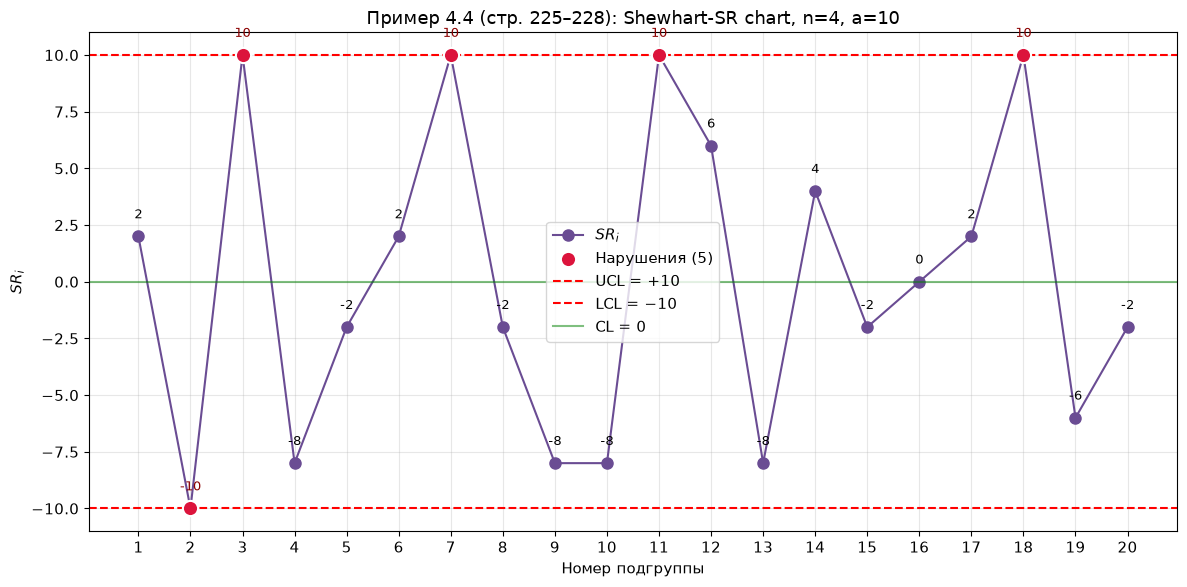

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(1, 21)
is_violation = (sr_vals >= a_book) | (sr_vals <= -a_book)
ax.plot(x, sr_vals, 'o-', color='#6A4C93', markersize=8, label='$SR_i$', zorder=2)
ax.scatter(x[is_violation], sr_vals[is_violation], s=120, color='crimson',
           edgecolors='white', linewidths=1.5, zorder=3,
           label=f'Нарушения ({is_violation.sum()})')
ax.axhline(a_book, color='red', ls='--', lw=1.5, label=f'UCL = +{a_book}')
ax.axhline(-a_book, color='red', ls='--', lw=1.5, label=f'LCL = −{a_book}')
ax.axhline(0, color='green', ls='-', alpha=0.5, label='CL = 0')

for xi, yi in zip(x, sr_vals):
    ax.annotate(f'{yi:.0f}', xy=(xi, yi), xytext=(xi, yi + 0.8),
                fontsize=9, ha='center', color='darkred' if abs(yi) >= a_book else 'black')

ax.set_xlabel('Номер подгруппы'); ax.set_ylabel('$SR_i$')
ax.set_title(f'Пример 4.4 (стр. 225–228): Shewhart-SR chart, n={n}, a={a_book}')
ax.set_xticks(x); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 7.2. Пример 4.5 — стр. 228–229 (Shewhart-SR chart с 2-of-2)

Правило 2-of-2 с предупреждающими границами $UWL=+6, LWL=-6$.

Сигналы: [('1-of-1', 2, np.float64(-10.0)), ('1-of-1', 3, np.float64(10.0)), ('1-of-1', 7, np.float64(10.0)), ('2-of-2', 10, (np.float64(-8.0), np.float64(-8.0))), ('1-of-1', 11, np.float64(10.0)), ('2-of-2', 12, (np.float64(10.0), np.float64(6.0))), ('1-of-1', 18, np.float64(10.0))]


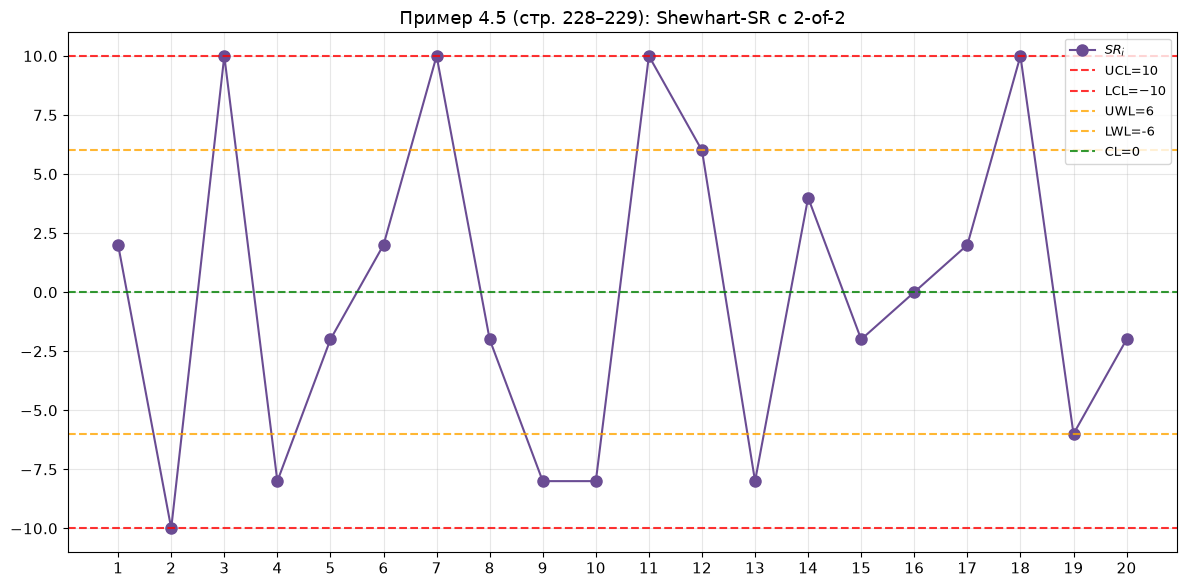

In [9]:
UWL, LWL = 6, -6
signals = []
for i in range(len(sr_vals)):
    if abs(sr_vals[i]) >= a_book:
        signals.append(('1-of-1', i+1, sr_vals[i]))
    if i >= 1:
        prev, cur = sr_vals[i-1], sr_vals[i]
        if (prev >= UWL and cur >= UWL) or (prev <= LWL and cur <= LWL):
            signals.append(('2-of-2', i+1, (prev, cur)))
print('Сигналы:', signals if signals else 'нет')

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x, sr_vals, 'o-', color='#6A4C93', markersize=8, label='$SR_i$', zorder=2)
for lvl, c, lbl in [(a_book, 'red', f'UCL={a_book}'),
                     (-a_book, 'red', f'LCL=−{a_book}'),
                     (UWL, 'orange', f'UWL={UWL}'),
                     (LWL, 'orange', f'LWL={LWL}'),
                     (0, 'green', 'CL=0')]:
    ax.axhline(lvl, color=c, ls='--', alpha=0.8, label=lbl)
ax.set_title('Пример 4.5 (стр. 228–229): Shewhart-SR с 2-of-2')
ax.set_xticks(x); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
# Проверка теста Уилкоксона по всем наблюдениям
all_vals = data_4_7a.flatten()
dev = all_vals - 0.0
nz = dev[dev != 0]
ranks = stats.rankdata(np.abs(nz), method='average')
signs = np.sign(nz)
T_plus_total = float(np.sum(ranks[signs > 0]))
SR_total = float(np.sum(signs * ranks))
n_tot = len(nz)
mu_T = n_tot * (n_tot + 1) / 4
sd_T = np.sqrt(n_tot * (n_tot + 1) * (2 * n_tot + 1) / 24)
z_stat = (T_plus_total - mu_T) / sd_T
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f'Глобальный знаково-ранговый тест Уилкоксона:')
print(f'  N = {n_tot}, T+ = {T_plus_total}, SR_total = {SR_total}')
print(f'  E(T+) = {mu_T}, SD(T+) = {sd_T:.4f}')
print(f'  Z = {z_stat:.4f}, p-value = {p_value:.4f}')

Глобальный знаково-ранговый тест Уилкоксона:
  N = 80, T+ = 1562.5, SR_total = -115.0
  E(T+) = 1620.0, SD(T+) = 208.4946
  Z = -0.2758, p-value = 0.7827


---

## 8. Сравнение со знаковой картой

**Источник:** Section 4.2.1.1 (Sign) vs Section 4.2.1.2 (Signed-rank).

| Аспект | Sign Chart | Signed-Rank Chart |
|--------|-----------|-------------------|
| Статистика | $SN_i = n_i^+ - n_i^-$ | $SR_i = \sum \phi(X-\mu_0) \cdot R$ |
| Предположения | непрерывность | непрерывность + **симметрия** |
| Диапазон $a$ | $0 < a \le n$ | $0 < a \le n(n+1)/2$ |
| Распределение в IC | $\text{BIN}(n, 0.5)$ | точный перебор $2^n$ |
| Мощность | ниже | **выше** |
| Distribution-free | для всех непрерывных $F$ | для всех непрерывных **симметричных** $F$ |

**Вывод:** знако-ранговая карта эффективнее, но требует симметрии. Для асимметричных данных используйте знаковую карту.

In [11]:
# Сравнение FAR и ARL для одинакового n
n_cmp = 10
a_sign, far_sign = calc_a_conservative(n_cmp)  # для SR-карты
a_sign_only = min(n_cmp, int(np.ceil(n_cmp / 2)))  # грубая оценка для знаковой

print(f'n = {n_cmp}')
print(f'\nЗнаковая карта (SN):')
from scipy.stats import binom
def p_sn_ge_a(n, a):
    if a > n: return 0.0
    t = int(np.ceil((n + a) / 2))
    if t > n: return 0.0
    return float(1 - binom.cdf(t - 1, n, 0.5))
for a in [3, 4, 5]:
    far_sn = min(2 * p_sn_ge_a(n_cmp, a), 1.0)
    print(f'  a={a}: FAR={far_sn:.6f}, ARL={1/far_sn:.2f}')

print(f'\nЗнако-ранговая карта (SR):')
for a in [10, 20, 30, 40]:
    far_sr = p_abs_sr_ge_a(n_cmp, a)
    print(f'  a={a}: FAR={far_sr:.6f}, ARL={1/far_sr:.2f}')

n = 10

Знаковая карта (SN):
  a=3: FAR=0.343750, ARL=2.91
  a=4: FAR=0.343750, ARL=2.91
  a=5: FAR=0.109375, ARL=9.14

Знако-ранговая карта (SR):
  a=10: FAR=0.625000, ARL=1.60
  a=20: FAR=0.322266, ARL=3.10
  a=30: FAR=0.130859, ARL=7.64
  a=40: FAR=0.037109, ARL=26.95


---

## 9. Моделирование длины серии

**Источник:** Section 4.2.1.2.3, стр. 201–202.

In [ ]:
# def simulate_rl_sr(n, mu0=0.0, a=None, n_sims=5000, shift=0.0):
#     """Моделирование длины серии для SR-карты."""
#     if a is None:
#         a, _ = calc_a_conservative(n)
#     rls = np.empty(n_sims, dtype=int)
#     for sim in range(n_sims):
#         t = 0
#         while True:
#             t += 1
#             sample = np.random.normal(mu0 + shift, 1.0, size=n)
#             sr, _ = sr_statistic(sample, mu0)
#             if abs(sr) >= a:
#                 break
#             if t > 100000:
#                 break
#         rls[sim] = t
#     return rls

# n_sim = 6
# a_sim, far_sim = calc_a_conservative(n_sim)
# rl = simulate_rl_sr(n_sim, 0.0, a_sim, 5000)
# print(f'n = {n_sim}, a = {a_sim}')
# print(f'ARL: {rl.mean():.2f} vs теория {1/far_sim:.2f}')
# print(f'MRL: {np.median(rl):.0f} vs теория {int(np.ceil(np.log(0.5)/np.log(1-far_sim)))}')
# print(f'SDRL: {rl.std():.2f} vs теория {np.sqrt(1-far_sim)/far_sim:.2f}')

# fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# axes[0].hist(rl, bins=50, color='#6A4C93', alpha=0.8, density=True, edgecolor='white')
# x_rl = np.arange(1, rl.max() + 1)
# axes[0].plot(x_rl, geom.pmf(x_rl, far_sim), 'r-', lw=2, label=f'GEO(FAR={far_sim:.4f})')
# axes[0].set_xlabel('N'); axes[0].set_ylabel('Плотность')
# axes[0].set_title(f'RL для SR-карты (n={n_sim}, a={a_sim})')
# axes[0].legend(); axes[0].grid(alpha=0.3)
# probplot(rl, dist=geom(far_sim), plot=axes[1]); axes[1].grid(alpha=0.3)
# plt.tight_layout(); plt.show()

In [ ]:
# # OOC-моделирование: сдвиг на 1σ
# n_ooc = 8
# a_ooc, far_ooc = calc_a_conservative(n_ooc)
# for shift in [0.0, 0.5, 1.0, 1.5, 2.0]:
#     rl_ooc = simulate_rl_sr(n_ooc, mu0=0.0, a=a_ooc, n_sims=2000, shift=shift)
#     print(f'shift={shift:.1f}σ: ARL_OOC = {rl_ooc.mean():.2f}, MRL_OOC = {np.median(rl_ooc):.0f}')

---

## 10. Пользовательские данные `data.csv`

**Файл:** `data/data.csv` — 10 строк × 14 столбцов (10 подгрупп по $n = 14$).

**Целевое значение по умолчанию:** медиана всех данных.

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Файл не найден: {DATA_PATH}')
df = pd.read_csv(DATA_PATH)
print('Первые 5 строк:'); display(df.head())
print(f'Размер: {df.shape}')
display(df.describe())

### 10.1. Проверка симметрии данных

In [ ]:
all_vals = df.values.flatten()
all_vals = all_vals[~np.isnan(all_vals)]

skew = stats.skew(all_vals)
kurt = stats.kurtosis(all_vals)
hl_stat, hl_p = hodges_lehmann_symmetric_test(all_vals)

print(f'Асимметрия (skewness) = {skew:.4f}  (0 = симметрия)')
print(f'Эксцесс (kurtosis) = {kurt:.4f}  (0 = нормальный)')
print(f'Ходжес-Леман: stat = {hl_stat:.4f}, p-value = {hl_p:.4f}')
if hl_p > 0.05:
    print('  → H0 (симметрия) НЕ отвергается при α = 0.05: SR-карта применима')
else:
    print('  → H0 (симметрия) отвергается: рассмотрите знаковую карту вместо SR-карты')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(all_vals, bins=30, color='#6A4C93', alpha=0.8, edgecolor='white', density=True)
axes[0].set_title('Гистограмма всех данных')
axes[0].axvline(np.median(all_vals), color='red', ls='--', label=f'медиана = {np.median(all_vals):.4f}')
axes[0].axvline(np.mean(all_vals), color='green', ls='--', label=f'среднее = {np.mean(all_vals):.4f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
probplot(all_vals, dist='norm', plot=axes[1]); axes[1].grid(alpha=0.3)
axes[1].set_title('QQ-plot vs N(0,1)')
plt.tight_layout(); plt.show()

### 10.2. Целевое значение по умолчанию

In [ ]:
n_obs = df.shape[1]
median_all = default_target_value(df, n_obs)
print(f'n = {n_obs}')
print(f'Медиана всех данных (μ₀ по умолчанию): {median_all:.6f}')
print(f'Среднее всех данных: {df.values.flatten().mean():.6f}')
print(f'Мин / Макс: {df.values.flatten().min():.4f} / {df.values.flatten().max():.4f}')

### 10.3. Сравнение подходов для текущего $n$

In [ ]:
cmp_rows = []
for approach, label in [('conservative', 'Консервативный'),
                         ('nearest', 'Ближайший'),
                         ('symmetric', 'Симметричный')]:
    if approach == 'conservative':
        a_, far_ = calc_a_conservative(n_obs, 0.0027)
    elif approach == 'nearest':
        a_, far_ = calc_a_nearest(n_obs, 0.05)
    else:
        a_, far_ = calc_a_symmetric(n_obs, 0.0027)
    cmp_rows.append({'Подход': label, 'a': a_, 'FAR': far_,
                     'ARL_IC': 1/far_ if far_ > 0 else np.inf})
df_n_cmp = pd.DataFrame(cmp_rows).round(6)
display(df_n_cmp)

### 10.4. Класс `SignedRankChart` — консервативный подход

In [ ]:
try:
    chart_cons = SignedRankChart(df, sample_size=n_obs,
                                  approach='conservative', far0=0.0027,
                                  coefficients_file=f'{PROJECT_ROOT}/src/utils/coefficients.json')
    lims = chart_cons.calculate_limits()
    print(f'Использованное μ₀ = {chart_cons.target_value:.6f}')
    print('Контрольные границы:')
    for k in ['CL', 'UCL', 'LCL', 'c_value', 'FAR', 'ARL_IC', 'MRL_IC', 'SR_max']:
        print(f'  {k} = {lims[k]}')
    print('\nТаблица сравнения подходов:')
    display(chart_cons.comparison_table)
    print('\nСводка:')
    display(pd.DataFrame([chart_cons.get_summary()]).T)
    print('\nЗначения SR:')
    display(chart_cons.get_sr_table()[['subgroup', 'sr', 'T_plus', 'positive', 'negative']])
    fig, ax = chart_cons.plot(fill_zones=True)
    plt.show()
except Exception as e:
    print(f'SignedRankChart недоступен ({e}). Используем локальные функции.')
    chart_cons = None

### 10.5. Локальная реализация карты (если класс недоступен)

In [ ]:
# Расчёт SR по всем подгруппам data.csv
sr_vals_csv = []
tp_vals_csv = []
for idx in range(len(df)):
    row = df.iloc[idx, :n_obs].values
    sr, tp = sr_statistic(row, median_all)
    sr_vals_csv.append(sr)
    tp_vals_csv.append(tp)
sr_vals_csv = np.array(sr_vals_csv)

a_cons = calc_a_conservative(n_obs, 0.0027)[0]
a_near = calc_a_nearest(n_obs, 0.05)[0]
a_sym = calc_a_symmetric(n_obs, 0.0027)[0]

print(f'n = {n_obs}, μ₀ = {median_all:.4f}')
print(f'Консервативный: a = {a_cons}')
print(f'Ближайший:      a = {a_near}')
print(f'Симметричный:   a = {a_sym}')
print(f'SR по подгруппам: {sr_vals_csv.tolist()}')

fig, ax = plt.subplots(figsize=(12, 6))
x_csv = np.arange(1, len(sr_vals_csv) + 1)
ax.plot(x_csv, sr_vals_csv, 'o-', color='#6A4C93', markersize=8, label='$SR_i$')
for lvl, c, lbl in [(a_cons, 'red', f'Консервативный a={a_cons}'),
                     (a_near, 'orange', f'Ближайший a={a_near}'),
                     (a_sym, 'purple', f'Симметричный a={a_sym}')]:
    ax.axhline(lvl, color=c, ls='--', lw=1.5, label=lbl)
    ax.axhline(-lvl, color=c, ls='--', lw=1.5)
ax.axhline(0, color='green', ls='-', alpha=0.5, label='CL=0')
ax.set_xlabel('Номер подгруппы'); ax.set_ylabel('$SR_i$')
ax.set_title(f'SR-карта на data.csv (n={n_obs}, μ₀={median_all:.4f})')
ax.set_xticks(x_csv); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 10.6. Явное задание μ₀ для сравнения

In [ ]:
targets = {'медиана': median_all, 'среднее': df.values.flatten().mean(), '0': 0.0}
for name, mu in targets.items():
    sr_list = [sr_statistic(df.iloc[i, :n_obs].values, mu)[0] for i in range(len(df))]
    print(f'μ₀ = {mu:>10.4f} ({name:>8}): SR = {[int(s) for s in sr_list]}, sum = {sum(sr_list):.0f}')

---

## 11. Итоги

### 11.1. Ключевые формулы

| Величина | Формула | Источник |
|----------|---------|----------|
| Абсолютное отклонение | $D_{ij} = |X_{ij} - \mu_0|$ | стр. 197 |
| Знако-ранговая статистика | $SR_i = \sum_j \phi(X_{ij}-\mu_0) R_{ij}$ | ур. 4.5, стр. 197 |
| Связь с Уилкоксоном | $SR_i = 2T_n^+ - n(n+1)/2$ | стр. 197 |
| Моменты | $E(SR_i)=0$, $\text{Var}(SR_i)=\frac{n(n+1)(2n+1)}{6}$ | стр. 200 |
| Границы | $LCL=-a$, $CL=0$, $UCL=+a$ | ур. 4.6, стр. 198 |
| Правило сигнала | $|SR_i| \ge a$ | стр. 198 |
| Длина серии | $N \sim \text{GEO}(FAR)$ | стр. 199 |
| ARL | $1/FAR$ | стр. 199 |
| MRL | $\lceil \ln 0.5 / \ln(1-FAR) \rceil$ | стр. 199 |

### 11.2. Три подхода к $a$

| Подход | Формула | Гарантия |
|--------|---------|----------|
| Консервативный | $P(SR \ge a) \le FAR_0/2$ | $FAR \le FAR_0$ |
| Ближайший | $\|P(\|SR\| \ge a) - \alpha\| \to \min$ | Нет |
| Симметричный | $a$ той же чётности, что и $S$, с $P(SR \ge a) \le FAR_0/2$ | $FAR \le FAR_0$ |

### 11.3. Примеры из книги

- **Пример 4.4** ($n=4$, $a=10$): воспроизведён, $FAR=0.125$, $ARL_{IC}=8$.
- **Пример 4.5** ($n=4$, 2-of-2): воспроизведён, сигналы на подгруппах 9-12.

### 11.4. Практические рекомендации

1. **Проверяйте симметрию** перед применением SR-карты. Если симметрия нарушена — используйте **знаковую карту**.
2. **Консервативный подход** — стандарт SPC.
3. **Знако-ранговая карта** требует $n \ge 10$–$13$ для приемлемого $ARL_{IC}$ (≈370–500).
4. Для $n = 1$ используйте **CUSUM-SR** или **EWMA-SR**.
5. **IC-робастность** для симметричных распределений — главное преимущество.
6. **Для `data.csv`** ($n = 14$) все три подхода дают близкие значения $a$.

### 11.5. Когда что использовать

| Ситуация | Рекомендация |
|----------|--------------|
| Данные симметричны, $n \ge 10$ | **SR-карта** (выше мощность) |
| Данные асимметричны | **SN-карта** (distribution-free) |
| $n = 1$ | CUSUM-SR / EWMA-SR |
| Малое $n$ ($< 8$) | Параметрическая карта (если нормальность) |
| Тяжёлые хвосты | SR-карта (робастнее) |